# The bank at a glance

Harborline's ratios by month, against real FDIC peers. Everything here reads the committed results, so it runs on a fresh clone.

> Harborline Bank is fictional. This is a demonstration on generated data and public datasets; no real customer, account or transaction of any real institution appears here.
>
> Nothing here is a credit decision, a fraud determination, a suspicious activity finding or investment advice.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl
from ledger_core.manifest import Manifest

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
m = Manifest.load(ROOT / "results" / "manifest.json")
plt.rcParams["figure.figsize"] = (9, 4)

In [2]:
for key in ("f01.total_assets", "f01.nim_q", "f01.efficiency_ratio_q", "f01.peer_nim_median", "f01.peer_count"):
    print(f"{key:<32}{m.text(key)}")

f01.total_assets                $1,033.6M
f01.nim_q                       5.60%
f01.efficiency_ratio_q          50.9%
f01.peer_nim_median             3.39%
f01.peer_count                  191


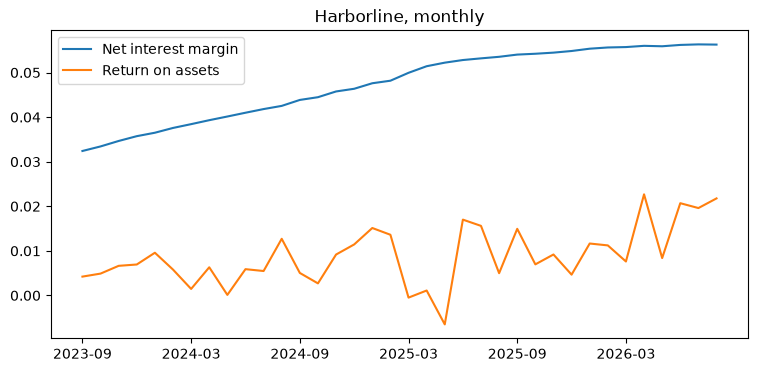

In [3]:
ratios = pl.read_parquet(ROOT / "results" / "f01" / "ratios_monthly.parquet")
fig, ax = plt.subplots()
ax.plot(ratios["month"], ratios["nim"], label="Net interest margin")
ax.plot(ratios["month"], ratios["roa"], label="Return on assets")
ax.set_xticks(ratios["month"][::6])
ax.legend()
ax.set_title("Harborline, monthly")
plt.show()

The margin sits high against the peers because most of the loan book is card and consumer installment lending. The peer comparison and its method are on the site's glance page.